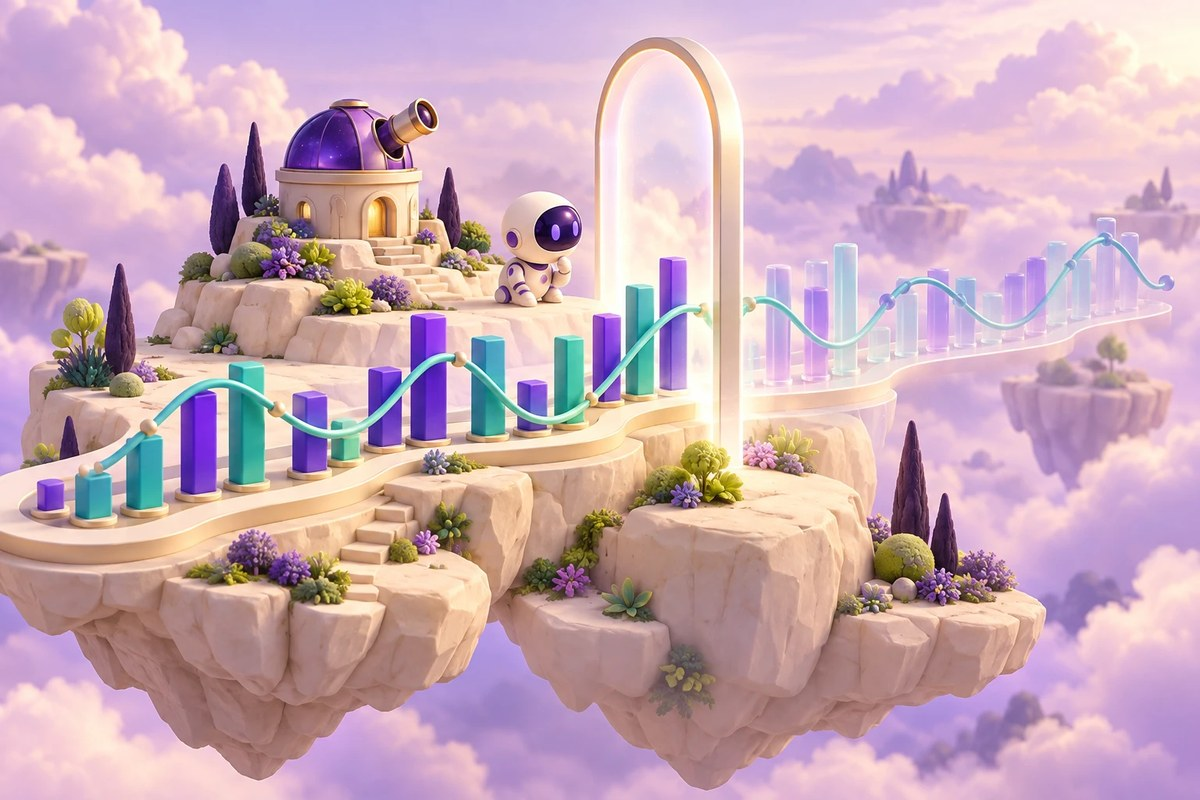

AI PATH · Временные ряды · Урок 049

# Четыре практики Terra AI

Трафик, рыночный ряд, голосовые команды и генетический поиск

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-049-goal"></a>
## Что вы разберёте

Разобрать четыре разных постановки задачи и связать в каждой входные данные, модель, наблюдаемый результат и способ проверки.

### Перед началом

- Базовый Python
- Понятия обучающей выборки и метрики
- Различие прогноза, классификации и поиска

### Что понадобится

- Историческая библиотека terra_ai==0.0.0.34
- Доступ через библиотеку к наборам ТРАФИК, ТРЕЙДИНГ и УМНЫЙ ДОМ
- Совместимая среда для аудио, интерактивного вывода и анимации посадки
- Вычислительный ресурс для нескольких независимых обучающих экспериментов

## Навигация по уроку

- [Цель и подготовка](#ai-049-goal)
- [Карта урока](#ai-049-map)
- [Одна среда, четыре задачи](#ai-049-section-01)
- [Прогнозируем последовательность трафика](#ai-049-section-02)
- [Разбираем рыночный эксперимент](#ai-049-section-03)
- [От звука к команде](#ai-049-section-04)
- [Порог уверенности классификатора](#ai-049-section-05)
- [Генетический поиск посадки](#ai-049-section-06)
- [Наблюдаем влияние параметров поиска](#ai-049-section-07)
- [Проверьте понимание](#ai-049-practice)
- [Источники и ограничения](#ai-049-provenance)

<a id="ai-049-map"></a>
## Карта урока

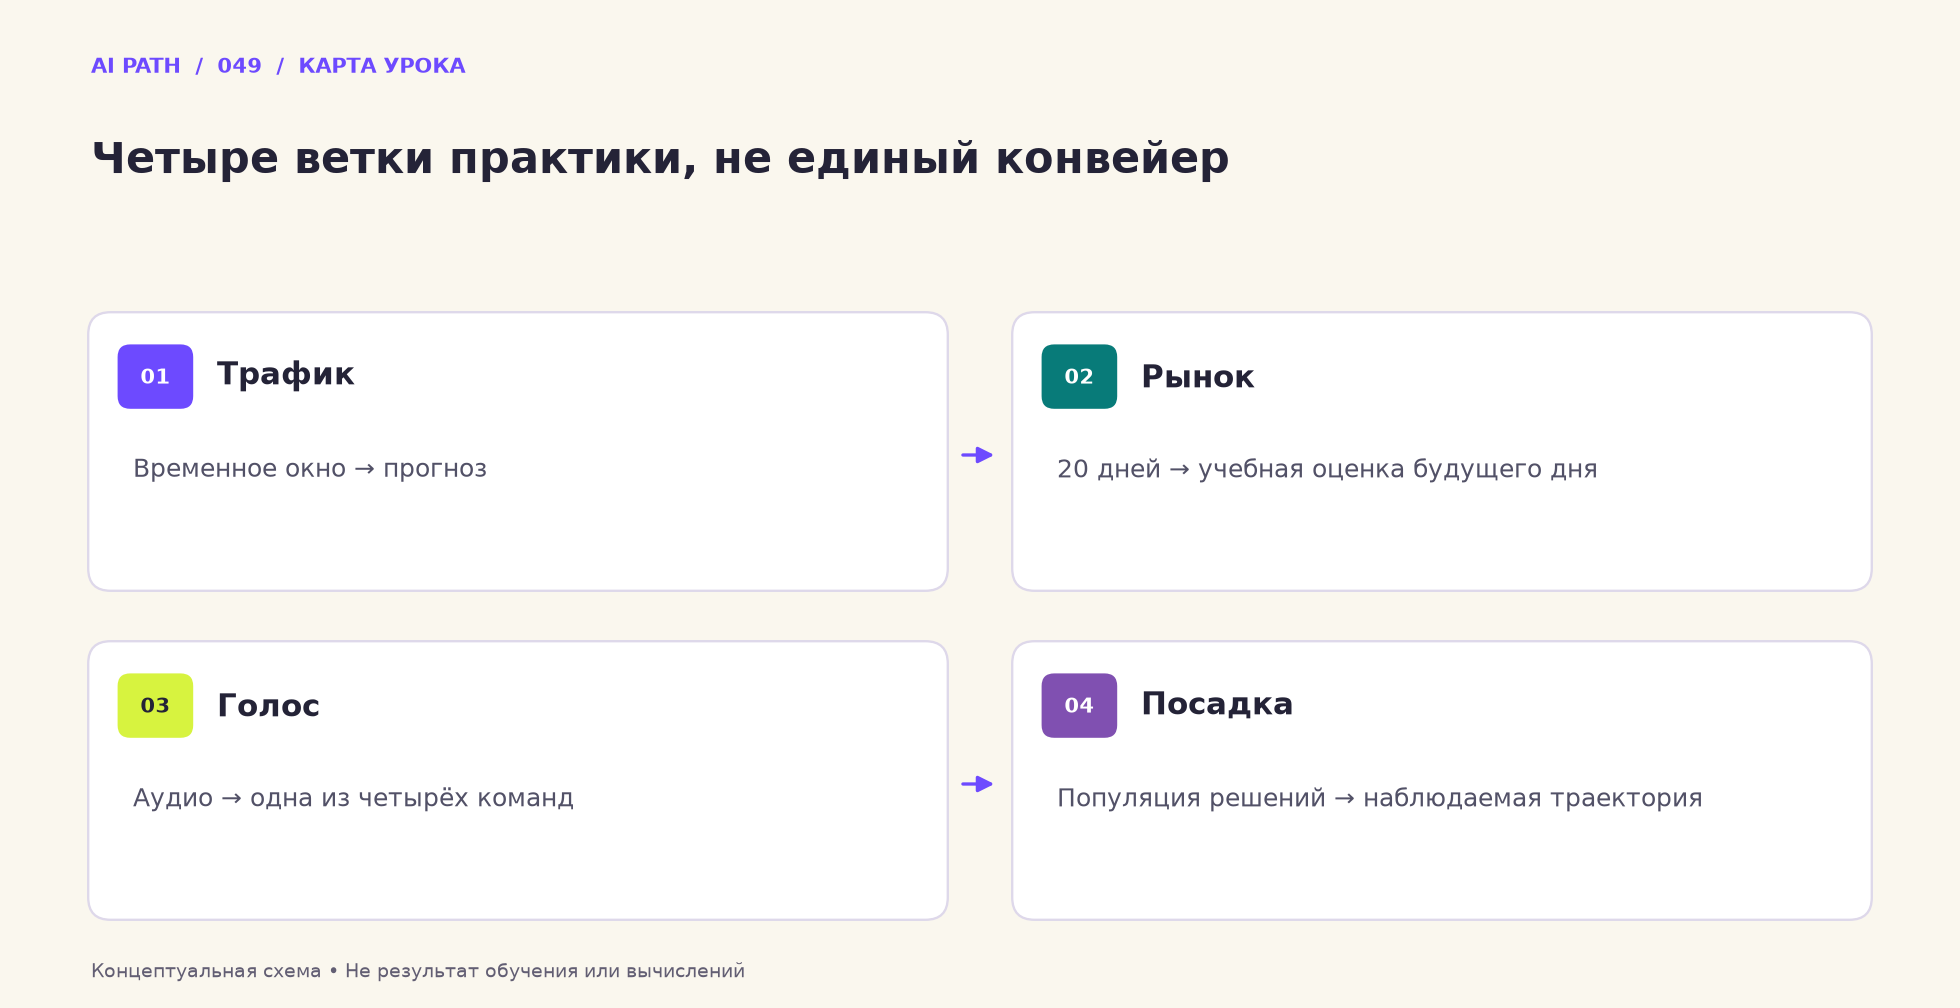

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Трафик** — Временное окно → прогноз
2. **Рынок** — 20 дней → учебная оценка будущего дня
3. **Голос** — Аудио → одна из четырёх команд
4. **Посадка** — Популяция решений → наблюдаемая траектория

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%22%D0%98%D0%BD%D1%82%D0%B5%D0%BD%D1%81%D0%B8%D0%B2_8_12_11_12_%D0%94%D0%BE%D0%BC%D0%B0%D1%88%D0%BD%D0%B5%D0%B5_%D0%B7%D0%B0%D0%B4%D0%B0%D0%BD%D0%B8%D0%B5_%E2%84%963_%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a id="ai-049-section-01"></a>
## 01 · Одна среда, четыре задачи

Практики независимы. Выберите одну ветку, проверьте её зависимости и не сравнивайте проценты разных задач между собой.

_Далее — исходные ячейки учебного материала._

In [16]:
#Установить terra_ai
!pip install terra_ai==0.0.0.34
#Импортировать модуль терра_ии
from terra_ai import терра_ии

# 1.Задание. Прогнозирование трафика компании

<a id="ai-049-section-02"></a>
## 02 · Прогнозируем последовательность трафика

Загрузчик создаёт временные генераторы; Conv1D преобразует окно наблюдений в прогноз. Проверьте, что проверочные даты идут после обучающих.

_Далее — исходные ячейки учебного материала._

In [19]:
# Загружаем базу трафик
терра_ии.загрузить_базу('ТРАФИК', справка=True)

Загрузка данных завершена 

Загружена база трафика компании



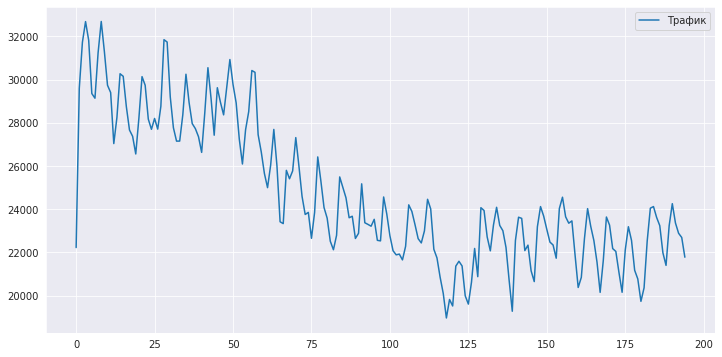

In [6]:
# Выводим примеры
старт = 0 # Начальное значение для отчета (от 0 до 1094)
финиш = 195 # Финальное значение для отчета (от 0 до 1095 (но должно быть больше стартового значения))
df = терра_ии.показать_пример_трафика(старт, финиш)

In [22]:
# Создаем выборки для обучения нейронной сети
обучающий_генератор, тестовый_генератор, данные = терра_ии.создать_выборки_трафик()

Выборки созданы успешно


## Создайте нейронную сеть
В которую будут входить слои рассмотренные на вебинаре, такие как:

*   Сверточный1D
*   Выравнивающий
*   Полносвязный


Создана модель нейронной сети!
Эпоха №1  Время обучения: 0.91c  Ошибка на обучающей выборке: 0.07176        Ошибка на прверочной выборке: 0.02987
Эпоха №2  Время обучения: 0.27c  Ошибка на обучающей выборке: 0.02883        Ошибка на прверочной выборке: 0.0106
Эпоха №3  Время обучения: 0.25c  Ошибка на обучающей выборке: 0.02268        Ошибка на прверочной выборке: 0.0119
Эпоха №4  Время обучения: 0.25c  Ошибка на обучающей выборке: 0.02117        Ошибка на прверочной выборке: 0.01138
Эпоха №5  Время обучения: 0.28c  Ошибка на обучающей выборке: 0.01948        Ошибка на прверочной выборке: 0.00888
Эпоха №6  Время обучения: 0.26c  Ошибка на обучающей выборке: 0.02089        Ошибка на прверочной выборке: 0.00829
Эпоха №7  Время обучения: 0.27c  Ошибка на обучающей выборке: 0.01896        Ошибка на прверочной выборке: 0.00804
Эпоха №8  Время обучения: 0.25c  Ошибка на обучающей выборке: 0.0196         Ошибка на прверочной выборке: 0.0082
Эпоха №9  Время обучения: 0.27c  Ошибка на обучающей

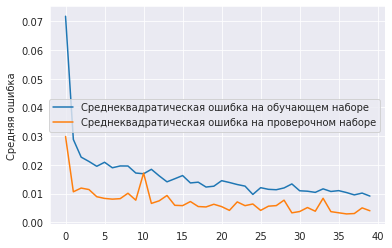

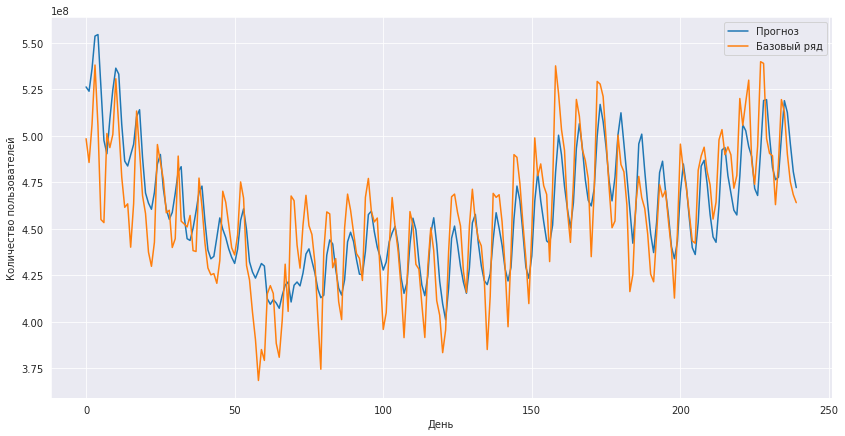

In [71]:
# Создаем нейронную сеть

слои = 'Сверточный1D-400 Дропаут-0.3 Сверточный1D-20 Дропаут-0.4 Выравнивающий Полносвязный-100 Дропаут-0.4 Полносвязный-10'

# создание модели
нейронка = терра_ии.создать_сеть(слои = слои,
                                 задача = 'трафик')
# Обучаем модель
терра_ии.обучение_модели_трафик(нейронка,
    обучающий_генератор, тестовый_генератор,        
    количество_эпох = 40)

терра_ии.тест_модели_трафика(нейронка, данные)

# 2.Задание. Трейдинг

<a id="ai-049-section-03"></a>
## 03 · Разбираем рыночный эксперимент

Пример использует «Полиметаллы», 20 анализируемых дней и один будущий день. Это историческая учебная модель, а не обещание доходности.

_Далее — исходные ячейки учебного материала._

In [86]:
# Загружаем базу трейдинг
терра_ии.загрузить_базу('ТРЕЙДИНГ', справка=True)

Загрузка данных завершена 

Загружены базы акций трех вариантов: полиметаллы, газпром и яндекс



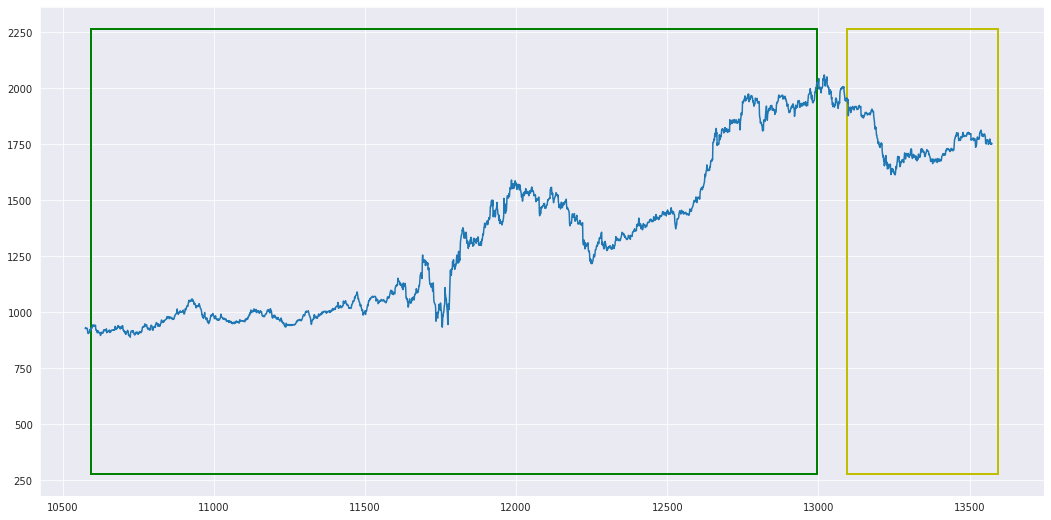

In [120]:
#Создание выборок
количество_анализируемых_дней=20
период_предсказания=1
(обучающая_выборка, метки_обучающей_выборки), (тестовая_выборка, метки_тестовой_выборки), данные  = терра_ии.создать_выборки_для_торговли(
    акции= 'Полиметаллы',
    количество_анализируемых_дней=количество_анализируемых_дней,
    период_предсказания=период_предсказания)
#Посмотреть данные
терра_ии.traide.show_data(данные)

## Создайте нейронную сеть
В которую будут входить слои рассмотренные на вебинаре, такие как:

*   Сверточный1D
*   Выравнивающий
*   Полносвязный
*   Дропаут
*   МаксПуллинг1D
*  Повтор







Создана модель нейронной сети!
Эпоха №1  Время обучения: 2.28c  Точность на обучающей выборке: 39.33%       Точность на прверочной выборке: 38.45%
Эпоха №2  Время обучения: 0.11c  Точность на обучающей выборке: 50.88%       Точность на прверочной выборке: 53.45%
Эпоха №3  Время обучения: 0.11c  Точность на обучающей выборке: 55.08%       Точность на прверочной выборке: 64.31%
Эпоха №4  Время обучения: 0.11c  Точность на обучающей выборке: 61.89%       Точность на прверочной выборке: 66.55%
Эпоха №5  Время обучения: 0.11c  Точность на обучающей выборке: 64.16%       Точность на прверочной выборке: 68.79%
Эпоха №6  Время обучения: 0.11c  Точность на обучающей выборке: 67.48%       Точность на прверочной выборке: 71.03%
Эпоха №7  Время обучения: 0.12c  Точность на обучающей выборке: 68.7%        Точность на прверочной выборке: 72.24%
Эпоха №8  Время обучения: 0.08c  Точность на обучающей выборке: 70.04%       Точность на прверочной выборке: 72.59%
Эпоха №9  Время обучения: 0.07c  Точность

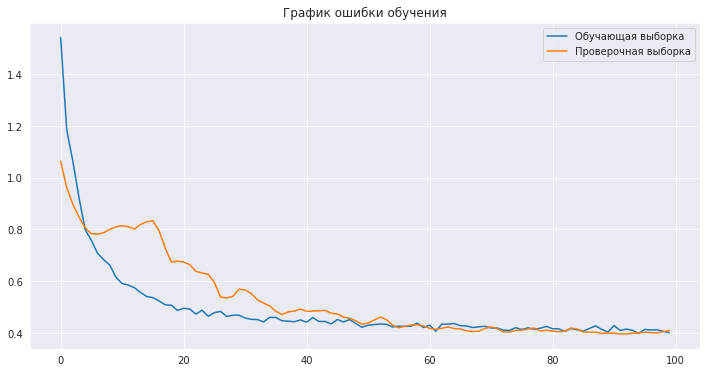

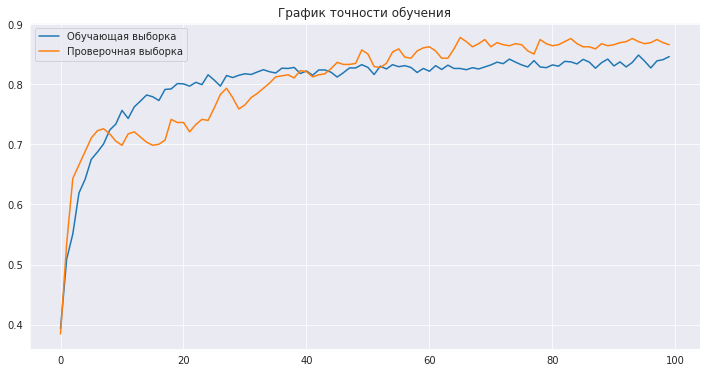

In [239]:
слои = 'Выравнивающий Повтор-4 Нормализация Дропаут-0.3 Сверточный1D-10 МаксПуллинг1D Нормализация Дропаут-0.3 \
Выравнивающий Повтор-35 Нормализация Дропаут-0.3 Сверточный1D-14 МаксПуллинг1D Нормализация Дропаут-0.3  \
Выравнивающий Полносвязный-600 Нормализация Дропаут-0.4 Полносвязный-30 Нормализация Дропаут-0.3  Полносвязный-3'
# Создаем модель
нейронка_1 = терра_ии.создать_сеть(
    слои = слои,
    входной_размер = терра_ии.инициализировать_под_базу(обучающая_выборка),
    задача = 'акции'
    )

# Обучаем модель
терра_ии.обучение_модели(
    нейронка_1,
    обучающая_выборка, метки_обучающей_выборки,
    тестовая_выборка, метки_тестовой_выборки,
    размер_пакета = 1000,
    количество_эпох = 100)
	


## Запустите тестирование модели
Используя функцию из terra_ai терра_ии.тест_модели_торговли()


Результат теста:
  * Количество отсчетов: 580
  * Правильных предсказаний: 505
  * Ошибочных предсказаний:  75

  * Точность предсказаний: 87.07%



Примеры распознавания


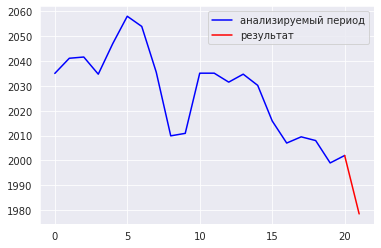

Тест №1
Модель предсказала падающий тренд:
Текущая цена:  2002.0
Цена через 1 дней(я): 1978.5




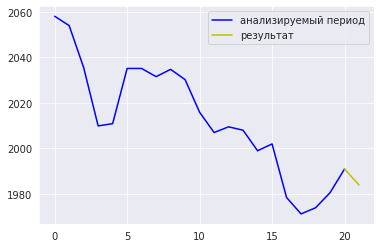

Тест №2
Модель предсказала нейтральный тренд:
Текущая цена:  1991.0
Цена через 1 дней(я): 1984.0




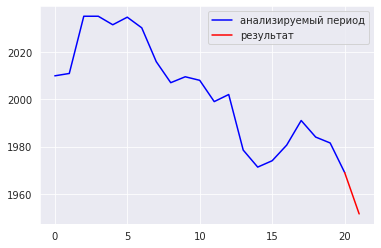

Тест №3
Модель предсказала падающий тренд:
Текущая цена:  1969.0
Цена через 1 дней(я): 1951.5




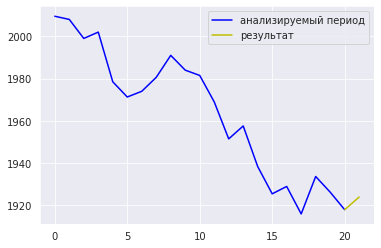

Тест №4
Модель предсказала нейтральный тренд:
Текущая цена:  1918.0
Цена через 1 дней(я): 1924.0




In [240]:
терра_ии.тест_модели_торговли(
    нейронка_1, 
    тестовая_выборка, метки_тестовой_выборки,
    данные,
    период_предсказания,
    20)


/usr/local/lib/python3.6/dist-packages/terra_ai/traide.py:366: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  axs[0].plot(l, returns['close'].values[[l]], '^', c='g')
/usr/local/lib/python3.6/dist-packages/terra_ai/traide.py:367: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  axs[0].plot(s, returns['close'].values[[s]], 'v', c='r')


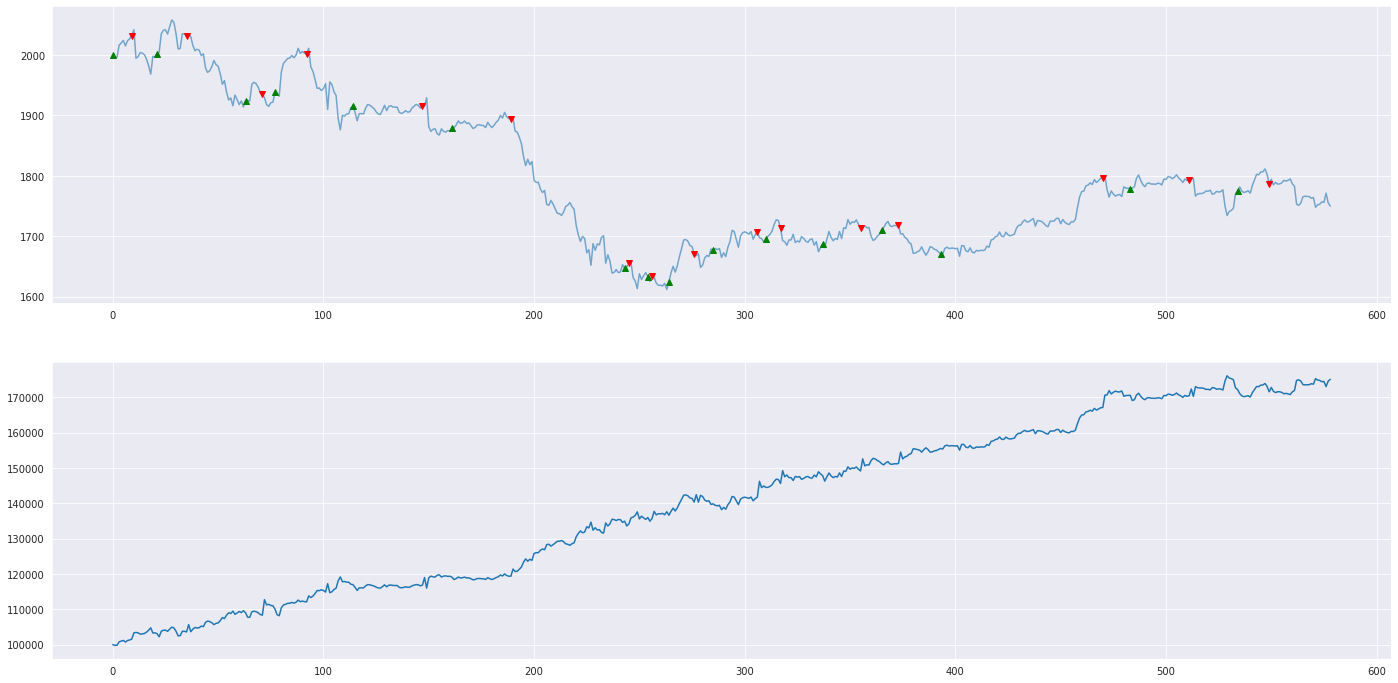

In [241]:
терра_ии.торговля(нейронка_1, тестовая_выборка, данные)

Результат теста:
  * Количество отсчетов: 580
  * Правильных предсказаний: 505
  * Ошибочных предсказаний:  75

#  * Точность предсказаний: 87.07%

# 3.Задание. Умный дом

<a id="ai-049-section-04"></a>
## 04 · От звука к команде

Сначала послушайте примеры и установите четыре класса. Классификатор должен оцениваться на записях, не участвовавших в обучении.

_Далее — исходные ячейки учебного материала._

In [242]:
# Загружаем базу голосовых команд для умного дома
терра_ии.загрузить_базу('УМНЫЙ ДОМ', справка=True)

Загрузка данных завершена 

Загружена база голосовых команд для умного дома



Пример голосовой команды «Кондиционер»:


Спектр голосовой команды:


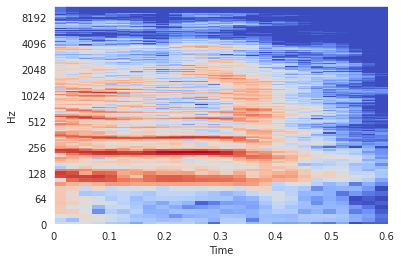

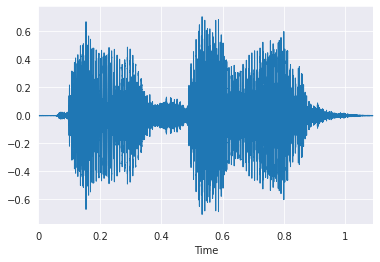



Пример голосовой команды «Свет»:


Спектр голосовой команды:


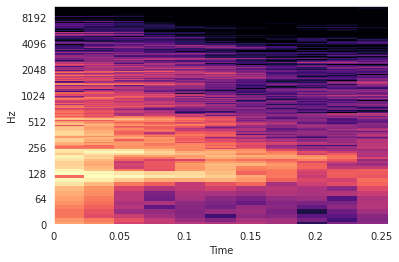

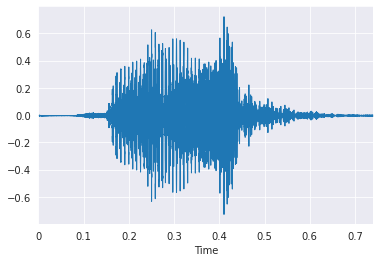



Пример голосовой команды «Телевизор»:


Спектр голосовой команды:


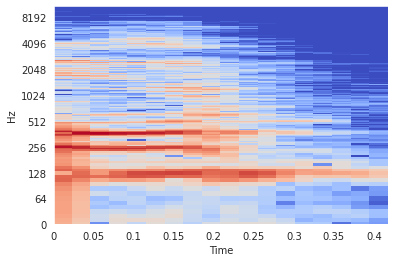

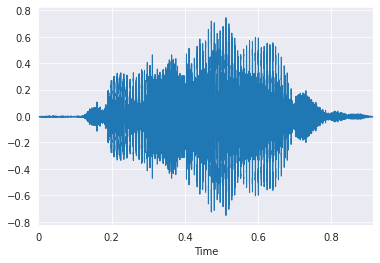



Пример голосовой команды «Фон»:


Спектр голосовой команды:


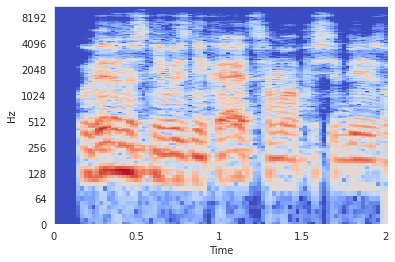

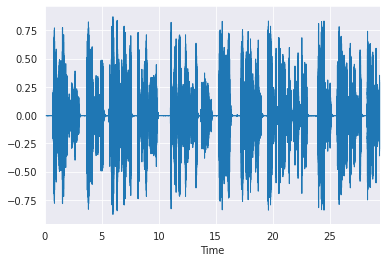

In [243]:
терра_ии.показать_примеры_голосовых_команд()

In [244]:
# Создаем обучающую и проверочную выборки
(обучающая_выборка, метки_обучающей_выборки), (тестовая_выборка, метки_тестовой_выборки) = терра_ии.создать_выборки_голосовых_команд()



Данные успешно загружены. Обработано: 362 аудио

Время обработки: 8 мин 17.34 c


## Создайте нейронную сеть
В которую будут входить слои рассмотренные на вебинаре, такие как:

*   Сверточный2D
*   Выравнивающий
*   Полносвязный

<a id="ai-049-section-05"></a>
## 05 · Порог уверенности классификатора

У голосовой модели есть четыре выхода и тест с порогом 0.95. Обсудите, что делать с неуверенной или посторонней командой.

_Далее — исходные ячейки учебного материала._

In [254]:
# создание модели
слои = 'Сверточный2D-200 Сверточный2D-200 Выравнивающий Полносвязный-128 Полносвязный-4'

нейронка = терра_ии.создать_сеть(
    слои = слои,
    входной_размер = терра_ии.инициализировать_под_базу(обучающая_выборка),    
    задача = "умный дом"
    )

Создана модель нейронной сети!


Схема модели:


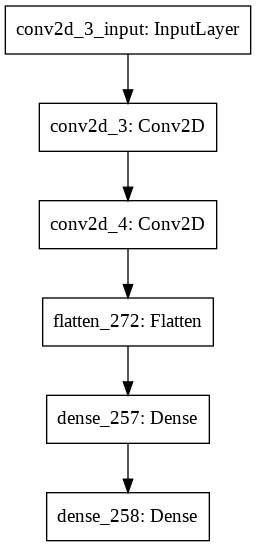

In [255]:
# Выводим структуру модели
терра_ии.схема_модели(нейронка)

## Обучите нейронную сеть
Используя свою модель, примените функцию из terra ai:
*   терра_ии.обучение_модели()

Эпоха №1  Время обучения: 16.33c Точность на обучающей выборке: 92.21%       Точность на прверочной выборке: 98.26%
Эпоха №2  Время обучения: 14.29c Точность на обучающей выборке: 99.31%       Точность на прверочной выборке: 99.77%
Эпоха №3  Время обучения: 14.32c Точность на обучающей выборке: 99.89%       Точность на прверочной выборке: 99.96%
Эпоха №4  Время обучения: 14.23c Точность на обучающей выборке: 99.95%       Точность на прверочной выборке: 99.85%
Эпоха №5  Время обучения: 14.34c Точность на обучающей выборке: 99.96%       Точность на прверочной выборке: 99.96%
Эпоха №6  Время обучения: 14.31c Точность на обучающей выборке: 100.0%       Точность на прверочной выборке: 99.94%
Эпоха №7  Время обучения: 14.27c Точность на обучающей выборке: 100.0%       Точность на прверочной выборке: 99.97%
Эпоха №8  Время обучения: 14.3c  Точность на обучающей выборке: 100.0%       Точность на прверочной выборке: 99.97%
Эпоха №9  Время обучения: 14.29c Точность на обучающей выборке: 100.0%  

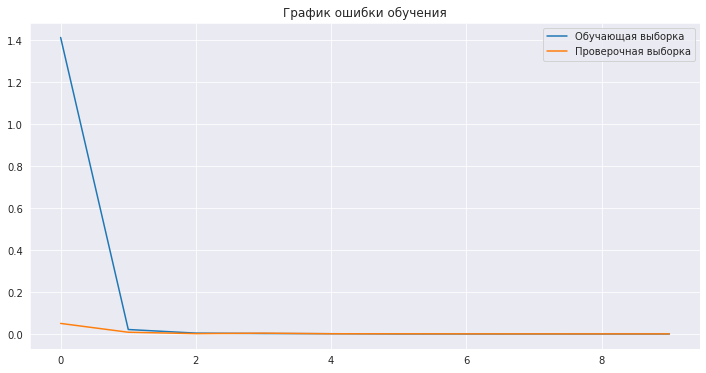

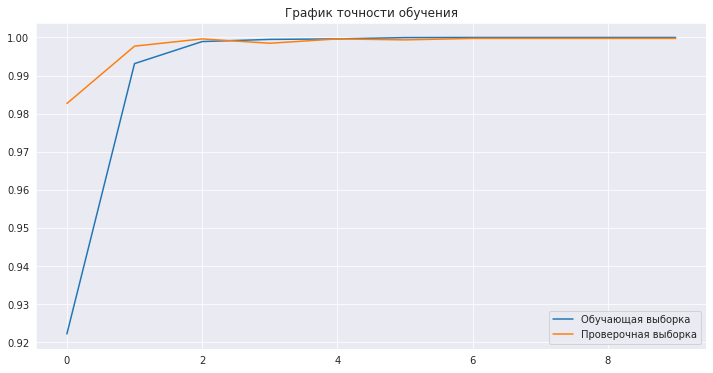

In [256]:
# Обучаем модель
терра_ии.обучение_модели(нейронка, обучающая_выборка, метки_обучающей_выборки,
                         тестовая_выборка, метки_тестовой_выборки,
                         размер_пакета =256,
                         количество_эпох=10
                         )

## Тестирование модели
Запустите два теста


Исходное аудио для проверки работы нейронной сети: 



Распознана команда: " КОНДИЦИОНЕР " (вероятность - 98.85 %)


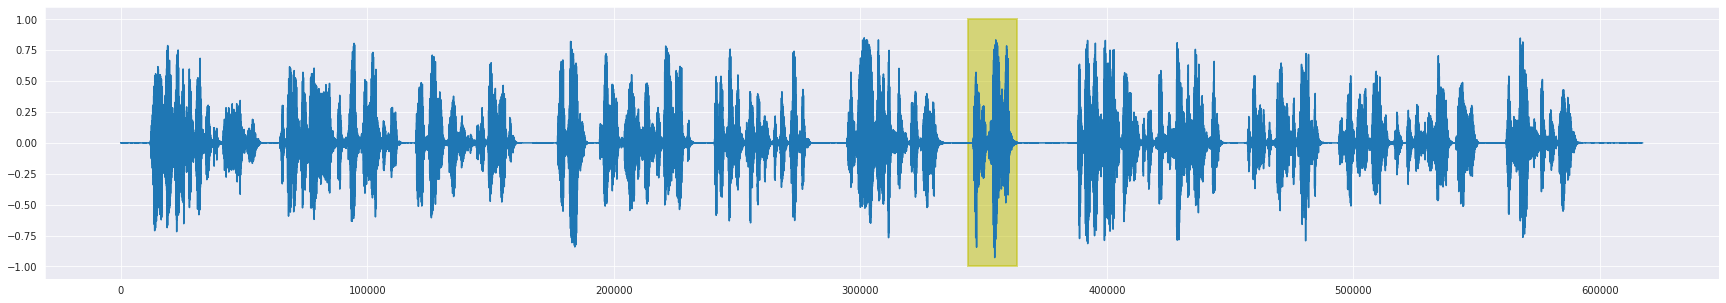

In [257]:
терра_ии.тест_модели_голосовых_команд(нейронка, порог=0.95)

Исходное аудио для проверки работы нейронной сети: 



Распознана команда: " СВЕТ " (вероятность - 95.66 %)


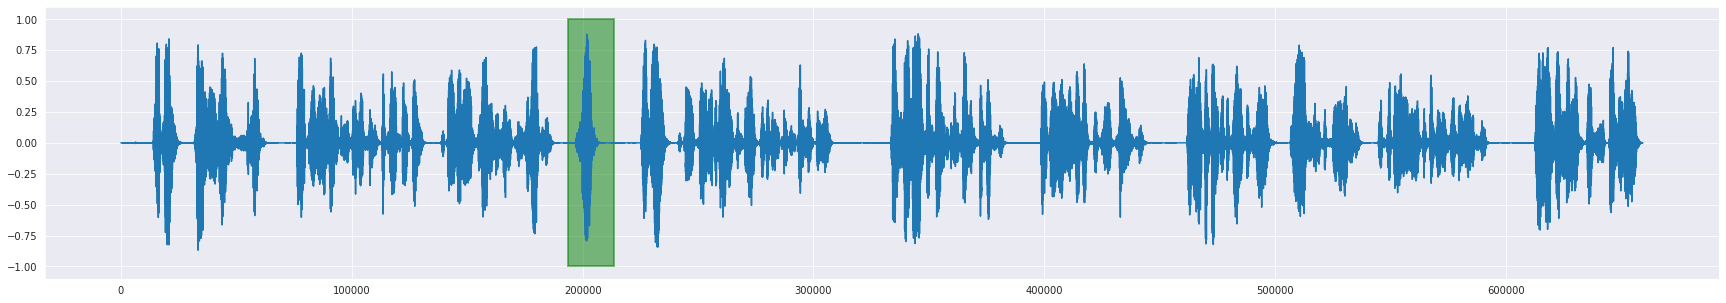

In [260]:
терра_ии.тест_модели_голосовых_команд(нейронка, порог=0.95)

# Точность на прверочной выборке: 99.97%

# 4.Задание. Генетика (посадка корабля)

<a id="ai-049-section-06"></a>
## 06 · Генетический поиск посадки

Последняя ветка загружает отдельные модули и визуализацию ракеты. Здесь оценивается поведение найденного решения, а не точность классификации.

_Далее — исходные ячейки учебного материала._

In [10]:
#Установить terra_ai
!pip install terra_ai==0.0.0.34
#Импортировать модуль терра_ии
from terra_ai import терра_ии

## Загрузите модули для работы с генетическим алгоритмом

In [11]:
#Загрузить модули
терра_ии.генетика.загрузить_модули()

Все модули установлены и готовы к работе


## Создайте дисплей для отображения видео

In [14]:
#Создать дисплей для отображения видео
терра_ии.генетика.создать_дисплей(1400, 900)

Виртуальный дисплей создан


## Запустите пример из базы без генетического алгоритма

In [15]:
#Пример без генетического алгоритма
терра_ии.генетика.показать_пример('Ракета')

NameError: ignored

## Подберите параметры для генетического алгоритма

*   размер_популяции
*   количество эпох
*   коэфицент_мутаци
*   количество_выживших



<a id="ai-049-section-07"></a>
## 07 · Наблюдаем влияние параметров поиска

Численность популяции, мутация и число выживших задаются явно. Меняйте по одному параметру и записывайте одинаковый критерий посадки.

_Далее — исходные ячейки учебного материала._

Выполняется эпоха № 0 Время на выполнение:  2.6 сек,   Награда для 3-x лучших ботов [  7 -18 -53]
Выполняется эпоха № 1 Время на выполнение:  1.6 сек,   Награда для 3-x лучших ботов [  2 -76 -78]
Выполняется эпоха № 2 Время на выполнение:  1.5 сек,   Награда для 3-x лучших ботов [ 39  16 -17]
Выполняется эпоха № 3 Время на выполнение:  1.5 сек,   Награда для 3-x лучших ботов [ -3 -20 -34]
Выполняется эпоха № 4 Время на выполнение:  1.3 сек,   Награда для 3-x лучших ботов [ 21 -10 -12]
Выполняется эпоха № 5 Время на выполнение:  1.0 сек,   Награда для 3-x лучших ботов [20 19  8]
Выполняется эпоха № 6 Время на выполнение:  1.1 сек,   Награда для 3-x лучших ботов [224  14  12]
Выполняется эпоха № 7 Время на выполнение:  0.9 сек,   Награда для 3-x лучших ботов [34 17  8]
Выполняется эпоха № 8 Время на выполнение:  1.0 сек,   Награда для 3-x лучших ботов [30 24  0]
Выполняется эпоха № 9 Время на выполнение:  1.2 сек,   Награда для 3-x лучших ботов [ 4 -1 -5]
Выполняется эпоха №10 Время на в

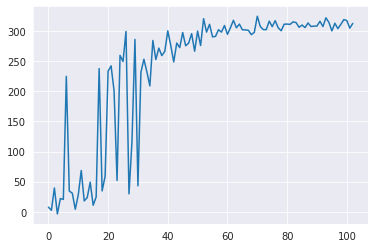

In [266]:
размер_популяции = 103
количество_эпох = 103
коэфицент_мутации = 0.3
количество_выживших = 43

# Заупустите генетический алгоритм
терра_ии.генетика.обучить_алгоритм(
    размер_популяции, 
    количество_эпох, 
    коэфицент_мутации, 
    количество_выживших
  )

## Посадите удачно космический корабль (2 раза)

In [1]:
терра_ии.генетика.посадить_корабль()

NameError: ignored

In [ ]:
терра_ии.генетика.посадить_корабль()

# [Второй вариант генетики с визуалиацией - результат 257 баллов](https://colab.research.google.com/drive/1_NTRAZxo6TUxZhXfseioD5k7XHKtJ1Kq#scrollTo=S0LgPzv-P3uL)

<a id="ai-049-practice"></a>
## Проверьте понимание

1. Какая форма входа нужна каждой из четырёх веток и почему она различается?
2. Как отдельно проверить ложные срабатывания при пороге голосовой модели 0.95?
3. Какой наблюдаемый критерий успеха посадки заменит субъективное «выглядит хорошо»?

### Один самостоятельный эксперимент

Выберите одну ветку и проведите два опыта с изменением одного параметра: окна трафика, порога команды или мутации посадки.

**Критерий успеха:** Оба опыта используют одинаковые данные или сценарии; записаны изменённый параметр, критерий и наблюдения без переноса метрики на другие задачи.

<a id="ai-049-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/Trafic/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%22%D0%98%D0%BD%D1%82%D0%B5%D0%BD%D1%81%D0%B8%D0%B2_8_12_11_12_%D0%94%D0%BE%D0%BC%D0%B0%D1%88%D0%BD%D0%B5%D0%B5_%D0%B7%D0%B0%D0%B4%D0%B0%D0%BD%D0%B8%D0%B5_%E2%84%963_%22.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- Внешние наборы и Terra AI 0.0.0.34 требуют отдельного восстановления совместимости; код не запускался.
- Сохранённые проценты относятся к историческим запускам и не являются независимой оценкой.
- Назначение и внешние действия функции терра_ии.торговля следует проверить по реализации до запуска; разрешение на реальные операции из примера не следует.
- Аудио и анимация требуют совместимого интерактивного интерфейса; статический просмотр не подтверждает их работу.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.